All configuration and model checks passed.
Layer depths = [   0.   30.  120. 2200. 2900. 5000.]
Number of points per layer along Z = [ 7  6 50 14 38]
Spacing in each layer in meters = [ 4.39980454 15.76614049 41.66666667 50.         56.         62.5       ]
QSEIS output folders from past runs deleted!
QSEIS output folders from past runs deleted!
QSEIS output folders from past runs deleted!
QSEIS output folders from past runs deleted!
QSEIS output folders from past runs deleted!
QSEIS output folders from past runs deleted!
QSEIS output folders from past runs deleted!
QSEIS output folders from past runs deleted!
QSEIS output folders from past runs deleted!
QSEIS output folders from past runs deleted!
QSEIS output folders from past runs deleted!
QSEIS output folders from past runs deleted!
QSEIS output folders from past runs deleted!
QSEIS output folders from past runs deleted!
QSEIS output folders from past runs deleted!
QSEIS output folders from past runs deleted!
QSEIS output folders f

[Worker 4164067] Starting job Layer0Run0 at 00:08:19[Worker 4164068] Starting job Layer0Run1 at 00:08:19[Worker 4164069] Starting job Layer0Run2 at 00:08:19[Worker 4164070] Starting job Layer0Run3 at 00:08:19[Worker 4164071] Starting job Layer0Run4 at 00:08:19[Worker 4164074] Starting job Layer0Run7 at 00:08:19[Worker 4164072] Starting job Layer0Run5 at 00:08:19[Worker 4164073] Starting job Layer0Run6 at 00:08:19[Worker 4164076] Starting job Layer0Run9 at 00:08:19[Worker 4164075] Starting job Layer0Run8 at 00:08:19[Worker 4164077] Starting job Layer0Run10 at 00:08:19[Worker 4164078] Starting job Layer0Run11 at 00:08:19[Worker 4164080] Starting job Layer0Run13 at 00:08:19[Worker 4164083] Starting job Layer0Run16 at 00:08:19[Worker 4164079] Starting job Layer0Run12 at 00:08:19[Worker 4164081] Starting job Layer0Run14 at 00:08:19[Worker 4164082] Starting job Layer0Run15 at 00:08:19[Worker 4164086] Starting job Layer0Run19 at 00:08:19[Worker 4164087] Starting job Layer0Run20 at 00:08:19




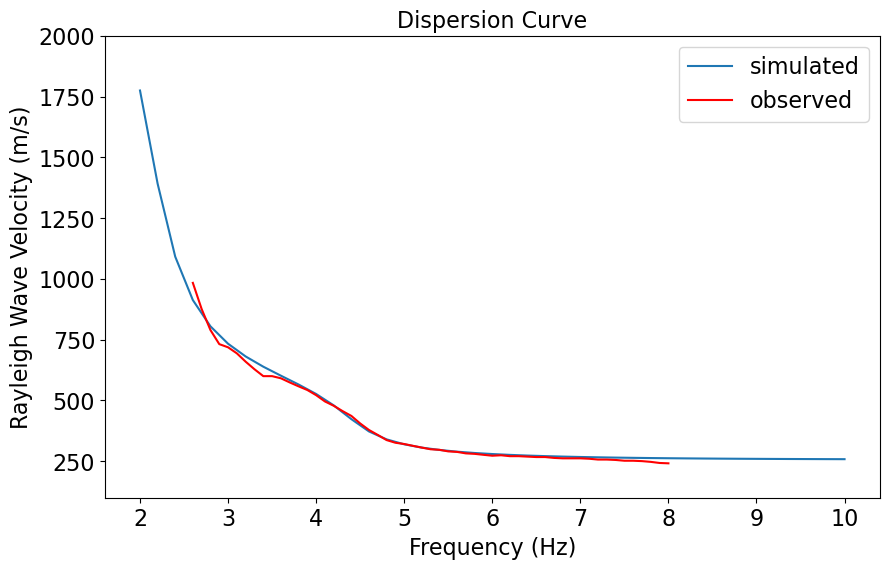

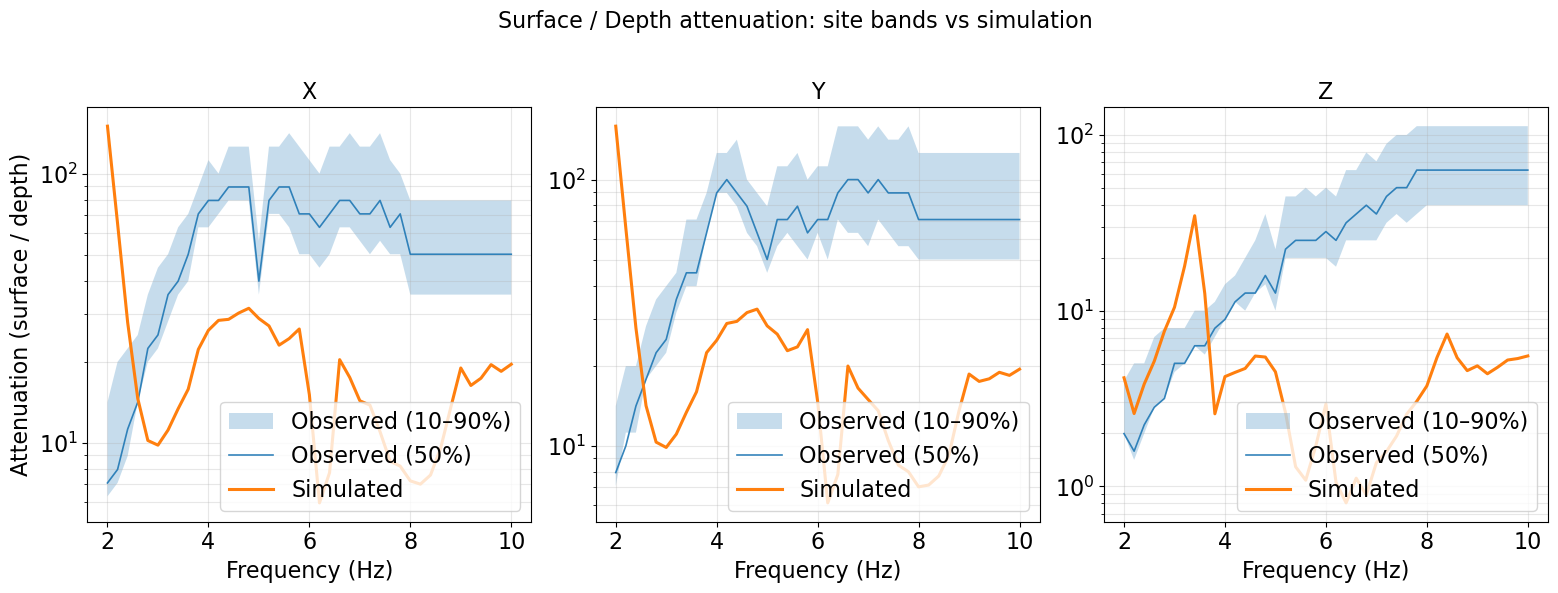

In [14]:
# script for computing the attenuation kernels per ring that will be used for
# obtaining the optimized weights per ring
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.io import savemat
from scipy.io import loadmat
import scipy.constants as const

from pysurf96 import surf96
from modules import configLoader
from modules import validateInputs
from modules import createDB
from modules import NNGeometryN
from modules import NNGeometryNN
from modules import gfLoader
from modules import simDisp
from modules import NNCompute
from modules import NNPP
from modules import plotUtils

def main():

    # load the config file
    configFile="/home/koley/CavityResults/SphAttnTutorialConfig/configParseAttnKernel.ini"
    config = configLoader.load_config(configFile)
    dispSavePath = '/home/koley/CavityResults/AllTutOut/AttnKernel/'
    allCavities = configLoader.loadCavities('/home/koley/CavityResults/SphFullRunConfig/SingleSphCavity.ini')
    validateInputs.validateInputs(config)
    # specify the ring bounds
    ringBounds = np.array([[100.0,  200.0],[200.0,  500.0],[500.0, 1000.0],[1000.0, 2000.0],
                           [2000.0, 3000.0],[3000.0, 4000.0],[4000.0, 5000.0],[5000.0, 6000.0]])

    nRing = len(ringBounds)
    fType = ['VForce','HForce']

    # two depth points for displacement saved per realization
    zList = np.array((0.0, 250.0))
    splitAll = createDB.createFinalInputsTD(config,zList)

    #print(f"Prepared {splitAll.shape[0]} total runs")
    print(f"Cores available: {config.cpuCoresQseis}")

    results = createDB.runMultiQseis(splitAll, config.inputPath, config.qseisExe, nWorkers = config.cpuCoresQseis)
    
    print("Database generation complete")
    
    # flag for pure Rayleigh wavefield in homogeneous half-space
    ifRay = config.ifRay

    # flag for plane P and S waves in homogeneous half space
    ifBody = config.ifBody

    # flag for wavefield simulation
    ifFullField = config.ifFullField

    saveHV = config.saveHV

    thickness = config.thickness # units in meters
    vs = config.vS # units in m/s
    vp = config.vP # units in m/s
    rho = config.rho # units in kg/m^3
    fMin = config.fMin; fMax = config.fMax; df = config.df;# units in Hz
    lambdaFrac = config.lambdaFrac # fraction
    lambdaRes = config.lambdaRes; #must be greater than 4
    
    # given a cuboidal domain should be greater than sqrt of 
    xMaxGF = config.xMaxGF # maximum horizontal offset upto which displacements will be used
    zMaxGF = config.zMaxGF # maximum depth upto which displacements will be used
    maxRec = config.maxRec # same value of number of receivers that qseis can handle in one go check qsglobal.h
    xCenter = config.xCenter; yCenter = config.yCenter
    xMin = xCenter-config.xExtent; xMax = xCenter+config.xExtent # minimum and maximum of the simulation domain in X-direction (EW)
    yMin = yCenter-config.yExtent; yMax = yCenter+config.yExtent # maximum and minimum of the simulation domain in Y-direction (NS)
    zMin = 0.0; zMax = config.zExtent # maximum and minimum of the simulation domain in Z-direction (depth)
    
    # check if the GFs are generated up to correct hoizontal offsets
    xDiag = (xMax-xMin)*np.sqrt(2); yDiag = (yMax-yMin)*np.sqrt(2)
    if(xMaxGF<xDiag or xMaxGF<yDiag):
        raise ValueError("xMaxGF must be >= sqrt(2)x(xMax-xMin) and sqrt(2)x(yMax-yMin)")
    
    if(zMaxGF<zMax):
        raise ValueError("zMaxGF must be greater >= zMax")
            
    domXYBounds = (xMin,xMax,yMin,yMax)
    
    itmAC = config.itmAC; itmAB = config.itmAB; etmCA = config.etmCA; etmBA = config.etmBA

    print('itmAC = ' + str(itmAC[0]) + ', ' + str(itmAC[1]) + ', ' + str(itmAC[2]))
    # make itmAC[2] negative, because in the configfile it is positive
    itmACUse = itmAC.copy(); itmACUse[2] = -np.abs(itmACUse[2])
    itmABUse = itmAB.copy(); itmABUse[2] = -np.abs(itmABUse[2])
    etmCAUse = etmCA.copy(); etmCAUse[2] = -np.abs(etmCAUse[2])
    etmBAUse = etmBA.copy(); etmBAUse[2] = -np.abs(etmBAUse[2])
    # just add one test-mass location, rather than all
    itmAll = np.vstack((itmACUse,))
    nTM = len(itmAll[:,0])
    G = const.G

    # an addition from the older version, where it is impoprtant to note that which cavity hosts
    # which test-mass
        
    tmInCavity = NNGeometryNN.findTMInCavity(allCavities, itmAll)
        
    # generate the grid size required
    gridSize = NNCompute.getGridSize(thickness,vp, vs, rho, fMin, fMax, lambdaFrac, lambdaRes)
    print('grid size in each layer before partitioning = ' + str(gridSize))
        
    # get the background gridsize in the layer hosting the cavities
    hBGAll = NNGeometryNN.getHBG(thickness,allCavities,gridSize)
    etaUse = 0.5
    radNow = allCavities[0]['radius']
    # now get the refinement extent for all cavities
    wallRefineWidthAll = NNGeometryNN.getRefineWidths(tmInCavity, allCavities, hBGAll,eta=etaUse,
                                                    minRefine=20.0,)
    print('wallRefineWidth = ')
    print(wallRefineWidthAll)
            
    refineBoxes = NNGeometryNN.makeRefineBoxesFromCavities(allCavities,wallRefineWidthAll,domainZBounds=(zMin,zMax))
        
    cubeTopAll = np.zeros((len(allCavities),))
    cubeBotAll = np.zeros((len(allCavities),))
    for boxNo, box in enumerate(refineBoxes):
        cubeTopAll[boxNo] = box.zMin
        cubeBotAll[boxNo] = box.zMax
    cubeTop = min(cubeTopAll)
    cubeBot = max(cubeBotAll)
    # new part added
    cavDepthAll = np.zeros((len(allCavities),))
    for cavNo, cav in enumerate(allCavities):    
        if(cav["shape"]=="cuboid"):
            cavDepthAll[cavNo] = cav["zC"]
        elif(cav["shape"] == 'sphere'):
            cavDepthAll[cavNo] = cav["zC"]
        else:
            raise ValueError('Unsupported cavity type')
    cavDepthUse = min(cavDepthAll)
        
    print("CubeTop = " + str(cubeTop) +  'CubeBot = ' + str(cubeBot))
    
    # some other inputs for simDisp
    tMax = config.tMax; nSamp = config.nSamp
    
    # specify the folder where you want to write all input files, should have rw access
    # fInpPath is the path where the Green's function database exists
    fInpPath = config.inputPath #like "/data/gravwav/koley/QseisInpN/"
    #fInpPath = "/data/gravwav/koley/SALVUSOut/"

    # outDispPath should have rw access and is used for saving temp displacementy files
    outDispPath = config.outDispPath # like "/data/gravwav/koley/OutDisp/"

    # GF components to be used
    components = ['fh-2.tz', 'fh-2.tr', 'fh-2.tt', 'fz-2.tz', 'fz-2.tr']

    # splitAll is necessary so load it
    nRea = config.nRea # number of realizations
    nRea = 1000
    # this file is created at the time of database generation
    splitFileName = fInpPath + 'splitAll.mat'
    splitMat = loadmat(splitFileName)
    splitAll = splitMat['splitAll']

    # source distribution parameters
    R1 = config.R1; R2 = config.R2
    print(config.srcDistri)
    print(config.R1); print(config.R2)
    nSrc = config.nSrc
    srcDistri = config.srcDistri
    scaleVH = config.scaleVH
    # flag if NN is computed directly without writing the displacemnet field
    onFlyNN = config.onFlyNN 

    # number of CPUs to be used for displacement and NN simulation
    nCPUDisp = config.cpuCoresDisp
    computeStrategy = config.computeStrategy

    # frequency axis to be used by simDisp  
    freqOut, idxFreq, df_native = simDisp.getFreqGrid(tMax, nSamp, fMin, fMax, df)
    nFreq = len(freqOut)

    splitAllNew = gfLoader.assembleQseisRuns(splitAll, fInpPath, components, outPath=None, fIndices=idxFreq, onlySplitAll = False, minVel=100.0)
    #splitAllNew = np.load(os.path.join(fInpPath,'splitAllNew.npy'))
    
    # in case only Rayleigh waves in homogeneous half space is used, Rayleigh wave phase velocity is needed
    if(ifRay):
        periods = 1/freqOut
        vR = surf96(thickness,vp,vs,rho,periods,wave="rayleigh",mode=1,velocity="phase",flat_earth=True)
    else:
        vR = None
    
    # generate the two points between which CC will be computed
    gridX = np.array((0.0,))
    gridY = np.array((0.0,))

    # need to loop for all source ring configs, and separately for V and H Force
    for fTypeNo, fTypeNow in enumerate(fType):

        # another loop for all the ring bounds, and then compute the attenuation kernels
        for ringNo, ringNow in enumerate(ringBounds):
            R1 = ringNow[0]; R2 = ringNow[1]
            print('Doing Force Type = ' + fTypeNow)
            # prepare containers
            dispSurfAllRea = np.zeros((nFreq,3))
            dispDepthAllRea = np.zeros((nFreq,3))
            attnZObs = np.zeros((nFreq,3), dtype=np.float64)
            attnXObs = np.zeros((nFreq,3), dtype=np.float64)
            attnYObs = np.zeros((nFreq,3), dtype=np.float64)

            for reaNo in range(0,nRea):
                print('Doing realization = ' +str(reaNo))
                # get the source distribution per realization
                xSrc, ySrc, azSrc, srcMeta =  simDisp.genAmbSrc(nSrc , mode = srcDistri, R1 = R1, R2 = R2, xMin=xMin, xMax=xMax, yMin=yMin,
                                               yMax=yMax, randomPhase=True, freqDependent=True, nFreq=nFreq, decoupledHV=config.decoupledHV,
                                               scaleVH = scaleVH)
                if(fTypeNow == 'VForce'):
                    srcMeta["ampH"] *= 0.0
                else:
                    srcMeta["ampV"] *= 0.0
                # in case the body wave in homogeneous half-space flag is turned on
                if(ifBody):
                    metaBody = simDisp.genBodySrc(nSrc, nFreq, eP = 1/3, eS = 2/3)       
                else:
                    metaBody=None
        
                if(ifBody):
                    dispTempSurf = simDisp.computeFullBodyDisp_parallel(zList[0], gridX, gridY, nSrc, freqOut, vp[0], vs[0], metaBody,
                                     n_workers=nCPUDisp)
                    dispTempDepth = simDisp.computeFullBodyDisp_parallel(-zList[1], gridX, gridY, nSrc, freqOut, vp[0], vs[0], metaBody,
                                     n_workers=nCPUDisp)
                elif(ifRay):
                    dispTempSurf = simDisp.computeRayleighDisp(zList[0], gridX, gridY, nSrc, freqOut, azSrc,
                                                        srcMeta["phiV"], srcMeta["ampV"], vR, vp[0], vs[0])
                    dispTempDepth = simDisp.computeRayleighDisp(-zList[1], gridX, gridY, nSrc, freqOut, azSrc,
                                                        srcMeta["phiV"], srcMeta["ampV"], vR, vp[0], vs[0])
                else:
                    # fullfield case
                    dispTempSurf, _, _, shmPathsSurf = simDisp.computeFullDispF(zList[0], gridX, gridY, itmAC, xSrc, ySrc, azSrc, srcMeta,idxFreq, freqOut, outDispPath,
                                splitAllNew, xMaxGF, fInpPath, nCPU=nCPUDisp, nChunk=20000, computeStrategy=computeStrategy,
                                saveHV=False, reduceNN=onFlyNN, nnMode=None, nnMeta=None)
                    dispTempDepth, _, _, shmPathsDepth = simDisp.computeFullDispF(zList[1], gridX, gridY, itmAC, xSrc, ySrc, azSrc, srcMeta,idxFreq, freqOut, outDispPath,
                                splitAllNew, xMaxGF, fInpPath, nCPU=nCPUDisp, nChunk=20000, computeStrategy=computeStrategy,
                                saveHV=False, reduceNN=onFlyNN, nnMode=None, nnMeta=None)

                dispSurfAllRea += (np.abs(dispTempSurf[:,0,:]))**2
                dispDepthAllRea += (np.abs(dispTempDepth[:,0,:]))**2

                if(ifFullField):
                    del dispTempSurf
                    simDisp.cleanup_sharedmem(shmPathsSurf)
                    del dispTempDepth
                    simDisp.cleanup_sharedmem(shmPathsDepth)
    
            # now get the attenuation
            attnSim = np.sqrt(dispSurfAllRea/dispDepthAllRea)
            dispSurfAllRea = dispSurfAllRea/nRea
            dispDepthAllRea = dispDepthAllRea/nRea

            dispAll = np.hstack((dispSurfAllRea, dispDepthAllRea))

            fName = 'dispRing' + str(ringNo) + fTypeNow + '.mat'
            # now save it
            savemat(os.path.join(dispSavePath,fName), {'dispAll':dispAll, 'freqOut':freqOut, 'zList':zList})

   # load Terziet Attenuation
    terzAttn = loadmat(os.path.join(config.siteASDPath,'attnModel.mat'))
    for i in range(0,3):
        attnXObs[:,i] = np.interp(freqOut,terzAttn['attnE'][:,0],terzAttn['attnE'][:,i+1])
        attnYObs[:,i] = np.interp(freqOut,terzAttn['attnN'][:,0],terzAttn['attnN'][:,i+1])
        attnZObs[:,i] = np.interp(freqOut,terzAttn['attnZ'][:,0],terzAttn['attnZ'][:,i+1])

    # get the theoretical Rayleigh transfer functions to check how it matches when full field
    # for a homogeneous half-space is invoked
    periods = 1/freqOut
    vR = surf96(thickness,vp,vs,rho,periods,wave="rayleigh",mode=1,velocity="phase",flat_earth=True)
    # active the plotting routine for consistent fontsizes
    plotUtils.set_plot_style("medium")
    terzDC = loadmat('/home/koley/pySeisNN1DFull/TERZ/DCTerziet.mat')
    
    fig,ax = plt.subplots(figsize=(10,6))
    ax.plot(freqOut,vR,label='simulated')
    ax.plot(terzDC['dcBigRing'][:,0],terzDC['dcBigRing'][:,1],'r',label='observed')
    ax.set_ylim(100,2000)
    ax.set_xlabel('Frequency (Hz)')
    ax.set_ylabel('Rayleigh Wave Velocity (m/s)')
    ax.set_title('Dispersion Curve')
    ax.legend()

    figAttn, axAttn = plotUtils.plotAttn(freqOut, attnSim, attnXObs, attnYObs, attnZObs)
    #axAttn[0].plot(freqOut,1/Th,'k',label='Rayleigh wavefield')
    #axAttn[1].plot(freqOut,1/Th,'k',label='Rayleigh wavefield')
    #axAttn[2].plot(freqOut,1/Tz,'k',label='Rayleigh wavefield')
    axAttn[0].legend()
    axAttn[1].legend()
    axAttn[2].legend()
if __name__ == "__main__":
    main()